# Lab 27: Budget Optimisation

This lab fits the reference Bayesian MMM from Lab 15, builds the same response curves as Lab 26, and reallocates a fixed weekly budget across the five Sedge Shoes channels to maximise expected contribution, rather than spreading it the way the historical plan happens to.
It then scores the plan on every posterior draw, adds the bounds Chapter 27 uses, and finally reproduces the plans the chapter prints.
It accompanies Chapter 27 of the book Marketing Mix Modelling.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from mmm_book import RANDOM_SEED
from mmm_book.optimise import ResponseCurves, band, greedy_allocate, ledger_betas
from mmm_book.plotting import mmm_style
from mmm_book.reference import national_aggregate, reference_model
from mmm_book.sedge import CHANNELS, correct_distribution, generate_sedge

mmm_style()

## Fitting the reference model

This reuses the shared national-aggregate reference model from `mmm_book.reference`, the model Lab 15 builds with the priors Lab 17 chooses.
Sampling uses the settings every lab uses (four chains of 1,000 draws after 1,000 warm-up steps, target acceptance 0.95), and the cell checks the fit before anything is read from it.

In [2]:
df = generate_sedge()
nat = national_aggregate(df)

with reference_model(nat):
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        cores=1,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        progressbar=False,
    )

n_divergent = int(idata.sample_stats["diverging"].sum())
r_hat = float(az.summary(idata, kind="diagnostics")["r_hat"].max())
print(f"divergent transitions: {n_divergent}, largest r_hat: {r_hat:.3f}")

beta_draws = {ch: idata.posterior[f"beta_{ch}"].to_numpy().reshape(-1) for ch in CHANNELS}
beta_mean = {ch: float(beta_draws[ch].mean()) for ch in CHANNELS}

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [intercept, trend, season_a, season_b, omega_launch, delta_promo, gamma_log_price, gamma_distribution, gamma_stock, gamma_temperature, gamma_rainfall, gamma_category, beta_tv, beta_search, beta_meta, beta_youtube, beta_ooh, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 25 seconds.


divergent transitions: 0, largest r_hat: 1.004


## Response curves in a common currency

`mmm_book.optimise.ResponseCurves` builds Lab 26's curves: a budget scales the channel's whole historical weekly plan, which passes through the channel's fixed adstock and saturation, with Television's GRPs valued at `TV_COST_PER_GRP` so that every channel is allocated in pounds.
Given the posterior-mean betas it gives the posterior mean curve, the average over draws that Chapter 27's objective $R_m(x)$ uses, because each draw's curve is the same shape scaled by its own beta.
The budget being reallocated is the sum of each channel's current average weekly spend, so every comparison below is like for like: the same total, spent differently.

In [3]:
curves = ResponseCurves(nat, beta_mean)
current = curves.current_money

print(f"total weekly budget: {curves.total_budget:,.0f} GBP")
for ch in CHANNELS:
    contribution = curves.money_contribution(ch, current[ch])
    print(f"  {ch:<10}{current[ch]:>10,.0f} GBP  ->  {contribution:>9,.0f} GBP a week")
print(f"current total contribution: {curves.total_contribution(current):,.0f} GBP a week")

total weekly budget: 115,385 GBP
  tv            26,923 GBP  ->     64,423 GBP a week
  search        26,923 GBP  ->     83,593 GBP a week
  meta          28,846 GBP  ->     88,670 GBP a week
  youtube       15,385 GBP  ->     15,699 GBP a week
  ooh           17,308 GBP  ->     26,024 GBP a week
current total contribution: 278,409 GBP a week


## Greedy marginal allocation

`greedy_allocate` is the allocator Chapter 27 describes.
It starts every channel at its lower bound (zero here), divides the remaining budget into 4,000 equal slices, and gives each slice to the channel whose next slice adds the most expected revenue, skipping any channel that has reached its upper bound.
As a channel receives more budget its marginal return falls, because every curve here bends over, so the allocation ends with every funded channel's marginal return roughly equal, the condition for an optimum when no bound binds.

In [4]:
unconstrained = greedy_allocate(curves)


def report(plan):
    print(f"{'channel':<10}{'current':>10}{'optimised':>11}{'marginal return':>17}")
    for ch in CHANNELS:
        step = 0.01 * current[ch]
        slope = (
            curves.money_contribution(ch, plan[ch] + step) - curves.money_contribution(ch, plan[ch])
        ) / step
        print(f"{ch:<10}{current[ch]:>10,.0f}{plan[ch]:>11,.0f}{slope:>17.2f}")
    gain = curves.total_contribution(plan) - curves.total_contribution(current)
    print(
        f"expected gain: {gain:,.0f} GBP a week ({gain / curves.total_contribution(current):.1%})"
    )


report(unconstrained)

channel      current  optimised  marginal return
tv            26,923     60,375             1.63
search        26,923     26,942             1.62
meta          28,846     28,067             1.62
youtube       15,385          0             1.13
ooh           17,308          0             1.53
expected gain: 18,786 GBP a week (6.7%)


## Scoring the plan on every posterior draw

The allocator worked on the posterior mean curve.
Chapter 27 asks how sure the gain is, so the plan is scored on each posterior draw: in this model each draw's curve is the mean curve scaled by that draw's beta, so the draw's gain is the sum over channels of its beta, relative to the mean, times the change in that channel's contribution.

In [5]:
def gain_draws(plan):
    total = 0.0
    for ch in CHANNELS:
        change = curves.money_contribution(ch, plan[ch]) - curves.money_contribution(
            ch, current[ch]
        )
        total = total + beta_draws[ch] / beta_mean[ch] * change
    return total


def score(label, plan):
    draws = gain_draws(plan)
    lo, hi = np.percentile(draws, [5, 95])
    print(
        f"{label:<14}gain {draws.mean():>7,.0f} GBP a week, 90% interval {lo:,.0f} to {hi:,.0f}, "
        f"P(beats current) {np.mean(draws > 0):.0%}"
    )


score("unconstrained", unconstrained)

unconstrained gain  18,786 GBP a week, 90% interval -18,114 to 49,248, P(beats current) 81%


## Why YouTube and OOH go to zero

The plan takes YouTube and OOH to zero, and that is a warning about the inputs, not a recommendation.
This national fit cannot separate Meta from YouTube, which share one paid-social budget (Lab 23), so it gives Meta much of their joint effect and YouTube a low return; OOH's curve is nearly straight with a mean marginal return of about 1.5, so once the other channels' marginal returns meet above that, every OOH pound loses.
The allocator treats the mean curves as exact, so a channel whose mean sits a little low loses every slice, however wide its interval (Lab 26).
Scoring on every draw shows the cost: the unconstrained plan beats the current mix in 81 per cent of draws, and its 90 per cent interval runs from a loss of about 18,000 pounds a week to a gain of about 49,000.
This is the estimation-error problem Chapter 38 opens with: an optimiser fed estimated returns rewards every flattering estimate and punishes every unflattering one.

## Bounds that reflect reality

Chapter 27's first-year bounds keep each channel within 20 per cent of current spend for the mature channels (Search, Meta and OOH) and 30 per cent for YouTube and Television.

In [6]:
lower, upper = band(curves, 0.20)
for ch in ("youtube", "tv"):
    lower[ch] = current[ch] * 0.70
    upper[ch] = current[ch] * 1.30
constrained = greedy_allocate(curves, lower, upper)
report(constrained)
score("constrained", constrained)

channel      current  optimised  marginal return
tv            26,923     34,999             1.96
search        26,923     27,300             1.60
meta          28,846     28,470             1.60
youtube       15,385     10,769             0.98
ooh           17,308     13,846             1.49
expected gain: 6,917 GBP a week (2.5%)


constrained   gain   6,917 GBP a week, 90% interval -1,365 to 13,955, P(beats current) 92%


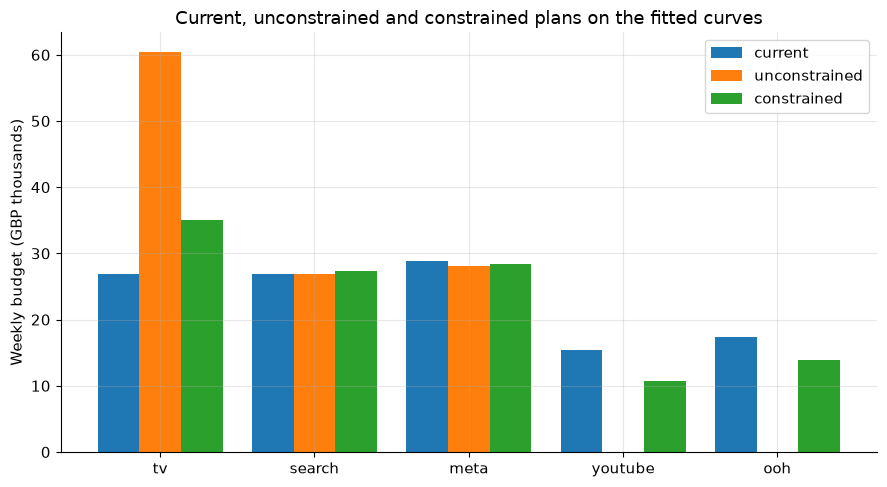

In [7]:
x = np.arange(len(CHANNELS))
width = 0.27

fig, ax = plt.subplots()
for i, (label, plan) in enumerate(
    [("current", current), ("unconstrained", unconstrained), ("constrained", constrained)]
):
    ax.bar(x + (i - 1) * width, [plan[ch] / 1e3 for ch in CHANNELS], width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(CHANNELS)
ax.set_ylabel("Weekly budget (GBP thousands)")
ax.set_title("Current, unconstrained and constrained plans on the fitted curves")
ax.legend()
fig.tight_layout()

## The plans printed in Chapter 27

The plans above use this run's fitted betas.
The plans Chapter 27 prints use the ledger curves instead: the curves a model would have if it had recovered the book's built-in true average returns exactly, so that the chapter's arithmetic rests on one known set of curves.
Running the same greedy allocator on them, once with no bounds and once with the chapter's first-year bounds, reproduces the chapter's two plans.
Revenue is printed to three decimals: the current mix's £12.715 million is the £12.72 million the book quotes.

In [8]:
ledger_nat = national_aggregate(correct_distribution(generate_sedge(seed=RANDOM_SEED)))
ledger = ResponseCurves(ledger_nat, ledger_betas(ledger_nat))

lo, hi = band(ledger, 0.20)
for ch in ("youtube", "tv"):
    lo[ch] = ledger.current_money[ch] * 0.70
    hi[ch] = ledger.current_money[ch] * 1.30

plans = {
    "current": ledger.current_money,
    "unconstrained": greedy_allocate(ledger),
    "constrained": greedy_allocate(ledger, lo, hi),
}
base = ledger.total_contribution(ledger.current_money) * 52
print(
    f"{'plan (GBPm)':<14}" + "".join(f"{ch:>9}" for ch in CHANNELS) + f"{'revenue':>10}{'gain':>9}"
)
for name, alloc in plans.items():
    revenue = ledger.total_contribution(alloc) * 52
    row = "".join(f"{alloc[ch] * 52 / 1e6:>9.2f}" for ch in CHANNELS)
    print(f"{name:<14}{row}{revenue / 1e6:>10.3f}{(revenue - base) / 1e3:>8,.0f}k")

plan (GBPm)          tv   search     meta  youtube      ooh   revenue     gain
current            1.40     1.40     1.50     0.80     0.90    12.715       0k
unconstrained      3.00     1.19     0.68     1.13     0.00    13.600     885k
constrained        1.82     1.22     1.20     1.04     0.72    13.152     437k


## Takeaway

Reallocating the same budget towards equal marginal returns raises expected contribution without spending a pound more: on this run's fitted curves the unconstrained plan adds about 18,800 pounds a week (6.7 per cent) and the bounded plan about 6,900 (2.5 per cent).
That upside is only as trustworthy as the curves behind it.
The unconstrained plan more than doubles Television and closes YouTube and OOH, and the YouTube cut leans on an individual estimate (1.02 against a true 2.0) that Lab 23 showed is unreliable because YouTube shares a budget with Meta.
Scoring on every posterior draw turns that worry into numbers: the bounded plan gains less on average but beats the current mix in 92 per cent of draws against 81 per cent, and its worst case is far smaller, which is the trade Chapter 27's bounds are designed to make.
A plan should also lean hardest on the channels an experiment has calibrated (Lab 24), and the case-study notebooks go further, re-solving the plan draw by draw on a model that estimates the curves' shapes as well as their heights (`notebooks/case_study/38_optimising_the_budget.ipynb`).